# Trabalho de IA - Resolução do Jogo do Labirinto usando Q- Learning Aproximado 

### Baixando as bibliotecas necessárias

In [1]:
%pip install matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Importando as bibliotecas

In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# Função que calcula a posição candidata. 
# Ela recebe a posição atual e a ação e, 
# a partir disso, calcula a posição candidata. 
def calcular_posicao_candidata(posicao_atual, acao):

    linha = posicao_atual[0]
    coluna = posicao_atual[1]

    if acao == "cima":

        return (linha - 1, coluna)

    if acao == "baixo":

        return (linha + 1, coluna)

    if acao == "direita":

        return (linha, coluna + 1)

    if acao == "esquerda":

        return (linha, coluna - 1)

    return posicao_atual # Se o agente recebe uma ação inválida, ele fica parado.

In [4]:
# Função que recebe a posição candidata e o mapa do labirinto e 
# verifica se a posição está dentro dos limites do mapa. 
def posicao_eh_valida(posicao_candidata, mapa_labirinto):

    qtd_linhas_mapa = len(mapa_labirinto)
    qtd_colunas_mapa = len(mapa_labirinto[0])

    linha = posicao_candidata[0]
    coluna = posicao_candidata[1]

    if ((0 <= linha < qtd_linhas_mapa) and (0 <= coluna < qtd_colunas_mapa)):

        return True

    return False 

# Função que recebe a posição candidata e o mapa do labirinto e 
# verifica se a posição é uma parede. 
def posicao_eh_parede(posicao_candidata, mapa_labirinto):

    linha = posicao_candidata[0]
    coluna = posicao_candidata[1]

    if mapa_labirinto[linha][coluna] == "#":

        return True 

    return False

# Função que recebe a posição candidata e o mapa do labirinto e 
# verifica se a posição é uma armadilha. 
def posicao_eh_armadilha(posicao_candidata, mapa_labirinto):

    linha = posicao_candidata[0]
    coluna = posicao_candidata[1]

    if mapa_labirinto[linha][coluna] == "T":

        return True 

    return False

# Função que recebe a posição candidata e o mapa do labirinto e 
# verifica se a posição é uma parede. 
def posicao_eh_saida(posicao_candidata, mapa_labirinto):

    linha = posicao_candidata[0]
    coluna = posicao_candidata[1]

    if mapa_labirinto[linha][coluna] == "E":

        return True 

    return False


In [5]:
# Função que recebe a posição atual, a ação e o mapa do labirinto e 
# devolve uma tupla que informa qual será a nova posição do agente, 
# qual será a recompensa dele para a ação e informa se ele chegou à saída.
def movimentar(posicao_atual, acao, mapa_labirinto):

    posicao_candidata = calcular_posicao_candidata(posicao_atual, acao)

    # A posição candidata está além dos limites do mapa, logo 
    # o agente não se mexe, tem penalidade de -3 e não chegou à saída. 
    if not posicao_eh_valida(posicao_candidata, mapa_labirinto):

        return (posicao_atual, -3, False)

    # A posição candidata é uma parede , logo o agente não se 
    # mexe, tem penalidade de -3 e não chegou à saída.
    if posicao_eh_parede(posicao_candidata, mapa_labirinto):

        return (posicao_atual, -3, False)

    # A posição candidata é uma armadilha, logo o agente 
    # avança, tem penalidade de -10 e não chegou à saída.
    if posicao_eh_armadilha(posicao_candidata, mapa_labirinto):

        return (posicao_candidata, -10, False)

    # A posição candidata é a saída, logo o agente 
    # avança para ela, tem recompensa de +30 e chegou à saída.
    if posicao_eh_saida(posicao_candidata, mapa_labirinto):

        return (posicao_candidata, +30, True)

    # É um simples movimento em uma célula livre. 
    else:

        return (posicao_candidata, -1, False)

In [6]:
%matplotlib inline
from IPython.display import display

In [7]:
# Função que ao receber o mapa do labirinto e a posição atual, desenha 
# o jogo. 
def desenhar_jogo(posicao_atual, mapa_labirinto):
    
    # Criamos um dicionário para mapear os símbolos do mapa 
    # à números a fim de facilitar o preenchimento com cor. 
    mapeamento_numerico = {

        ".": 0,  # Caminho livre
        "#": 1,  # Parede
        "S": 2,  # Início
        "E": 3,  # Saída
        "T": 4   # Armadilha
    }
    
    # Convertemos a matriz de strings para uma matriz numérica
    linhas = len(mapa_labirinto)
    colunas = len(mapa_labirinto[0])
    matriz_numerica = np.zeros((linhas, colunas))
    
    # Preenchemos a matriz numérica com os valores do dicionário. 
    for l in range(linhas):

        for c in range(colunas):

            simbolo = mapa_labirinto[l][c]

            matriz_numerica[l][c] = mapeamento_numerico.get(simbolo, 0)
            
    figura = plt.figure(figsize=(8, 6))
    
    # Criamos um mapeamento entre as cores e os símbolos do mapa:
    # 0=Branco (Caminho), 1=Preto (Parede), 2=Azul (Início), 3=Verde (Saída), 4=Vermelho (Armadilha)
    cmap_customizado = plt.cm.colors.ListedColormap(['white', 'black', 'blue', 'green', 'red'])
    
    plt.imshow(matriz_numerica, cmap=cmap_customizado, origin='upper', vmin=0, vmax=4)
    
    # Desenhando a posição atual do agente
    linha_jogador, coluna_jogador = posicao_atual
    
    marcador, = plt.plot(coluna_jogador, linha_jogador, marker='o', color='gold', markersize=15, markeredgecolor='black', label='Jogador')
    
    plt.xticks(range(colunas))
    plt.yticks(range(linhas))
    plt.grid(True, which='both', color='gray', linestyle='-', linewidth=0.5)
    
    # plt.show(block=False)

    return figura, marcador

In [ ]:
# Função que recebe a posição atual, ação, mapa e posição de saída 
# e extrai as caracterpisticas. 
def extrair_caracteristicas(posicao_atual, acao, mapa_labirinto, posicao_saida):

    posicao_candidata = calcular_posicao_candidata(posicao_atual, acao)

    colisao = 0.0
    armadilha = 0.0
    saida = 0.0 

    if not posicao_eh_valida(posicao_candidata, mapa_labirinto) or posicao_eh_parede(posicao_candidata, mapa_labirinto):

        posicao_resultante = posicao_atual

        colisao = 1.0 

    else:
        
        posicao_resultante = posicao_candidata

        if posicao_eh_armadilha(posicao_candidata, mapa_labirinto):

            armadilha = 1.0 

        if posicao_eh_saida(posicao_candidata, mapa_labirinto):

            saida = 1.0 

    # Vamos calcular a distância normalizada até a saída usando a distância
    # de Manhattan. 

    linha_resultante = posicao_resultante[0]
    coluna_resultante = posicao_resultante[1]

    linha_saida = posicao_saida[0]
    coluna_saida = posicao_saida[1]

    distancia_absoluta = abs(linha_resultante - linha_saida) + abs(coluna_resultante - coluna_saida)

    max_distancia_possivel = (len(mapa_labirinto) - 1) + (len(mapa_labirinto[0] - 1))

    distancia_normalizada = distancia_absoluta / max_distancia_possivel

    bias = 1.0 # Ajuda nos cálculos da IA 

    vetor_caracteristicas = np.array([

        bias, colisao, armadilha, saida, distancia_normalizada
    ], dtype=np.float64)

    return vetor_caracteristicas


In [ ]:
# Função que calula o q_valor aproximado realizando o produto 
# escalar entre os pesos e as caracteristicas. 
def calcular_q(pesos, vetor_caracteristicas):

    return np.dot(pesos, vetor_caracteristicas)

In [ ]:
# Define qual ação o agente vai tomar usando a estratégia epsilon-greedy.
# Tem uma chance (epsilon) de testar direções aleatórias para explorar o labirinto,
# senão ele escolhe a ação com maior valor estimado de Q.
def escolher_acao(posicao_atual, posicao_saida, mapa_labirinto, epsilon, acoes_disponiveis, gerador_aleatorio, pesos):

    # Sortei um número entre 0 e 1 
    if gerador_aleatorio.random() < epsilon:

        # O agente vai explorar. Ele escolhe uma das ações com igual probabilidade. 
        return gerador_aleatorio.choice(acoes_disponiveis)

    # O agente resolve aproveitar e vai no maior Q para pontuar mais.
    # Ele calcula o q de cada ação disponível e guarda em um diconário. 
    # Pega a ação ou as ações que atingiram o maior q e sorteia uma aleatoriamente.  
    valores_q = {}

    for acao in acoes_disponiveis:

        caracteristicas = extrair_caracteristicas(posicao_atual, acao, mapa_labirinto, posicao_saida)

        q_atual = calcular_q(pesos, caracteristicas)

        valores_q[acao] = q_atual

    maior_q = max(valores_q.values())

    acoes_maior_q = []

    for acao, q in valores_q.items():

        if q == maior_q:

            acoes_maior_q.append(acao)

    return gerador_aleatorio.choice(acoes_maior_q)

            


In [ ]:
# Atualiza os pesos usando Q-Learning
def atualizar_pesos(pesos_atuais, caracteristicas_atuais, recompensa, 
                    proxima_posicao, chegou_saida, mapa_labirinto, alpha, gama, acoes_disponiveis, posicao_saida):

    # Calculando a previsão anterior. 
    q_atual = calcular_q(pesos_atuais, caracteristicas_atuais)

    # Calculando o melhor valor futuro 
    if chegou_saida:

        melhor_q_futuro = 0.0 # Se chegou à saída, não tem próxima ação. 

    else:

        q_futuros = []

        for acao in acoes_disponiveis:

            caracteristicas_futuras = extrair_caracteristicas(proxima_posicao, acao, mapa_labirinto, posicao_saida)

            q_futuro = calcular_q(pesos_atuais, caracteristicas_futuras)

            q_futuros.append(q_futuro)

        melhor_q_futuro = max(q_futuros)

    novo_alvo = recompensa + gama * melhor_q_futuro

    erro_temporal = novo_alvo - q_atual

    novos_pesos = pesos_atuais + alpha * erro_temporal * caracteristicas_atuais

    return novos_pesos



In [ ]:
def treinar_episodio(mapa_labirinto, pesos, alpha, gama, epsilon, acoes_disponiveis, gerador_aleatorio, limite_movimentos, posicao_inicial, posicao_saida):

    posicao_atual = posicao_inicial
    pontuacao_acumulada = 0
    contador_movimentos = 0

    chegou_saida = posicao_eh_saida(posicao_atual, mapa_labirinto)

    while ((chegou_saida != True) and (contador_movimentos < limite_movimentos)):

        acao_escolhida = escolher_acao(posicao_atual, posicao_saida, mapa_labirinto, epsilon, acoes_disponiveis, gerador_aleatorio, pesos)

        caracteristicas = extrair_caracteristicas(posicao_atual, acao_escolhida, mapa_labirinto, posicao_saida)

        proxima_posicao, recompensa, chegou_saida = movimentar(posicao_atual, acao_escolhida, mapa_labirinto)

        pesos = atualizar_pesos(pesos, caracteristicas, recompensa, proxima_posicao, chegou_saida, mapa_labirinto, alpha, gama, acoes_disponiveis, posicao_saida)

        posicao_atual = proxima_posicao

        pontuacao_acumulada += recompensa

        contador_movimentos += 1

    return pesos, pontuacao_acumulada, contador_movimentos, chegou_saida


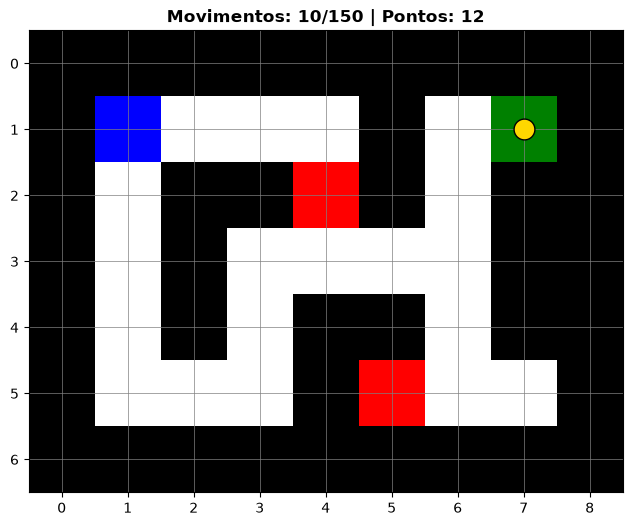

--- O JOGO COMEÇOU ---

 -> Direção escolhida: DIREITA
 -> Posição Atual: (1, 2)
 -> Recompensa recebida: -1
 -> Pontuação Total: -1
 -> Direção escolhida: DIREITA
 -> Posição Atual: (1, 3)
 -> Recompensa recebida: -1
 -> Pontuação Total: -2
 -> Direção escolhida: DIREITA
 -> Posição Atual: (1, 4)
 -> Recompensa recebida: -1
 -> Pontuação Total: -3
 -> Direção escolhida: BAIXO
 -> Posição Atual: (2, 4)
 -> Recompensa recebida: -10
 -> Pontuação Total: -13
 -> Direção escolhida: BAIXO
 -> Posição Atual: (3, 4)
 -> Recompensa recebida: -1
 -> Pontuação Total: -14
 -> Direção escolhida: DIREITA
 -> Posição Atual: (3, 5)
 -> Recompensa recebida: -1
 -> Pontuação Total: -15
 -> Direção escolhida: DIREITA
 -> Posição Atual: (3, 6)
 -> Recompensa recebida: -1
 -> Pontuação Total: -16
 -> Direção escolhida: CIMA
 -> Posição Atual: (2, 6)
 -> Recompensa recebida: -1
 -> Pontuação Total: -17
 -> Direção escolhida: CIMA
 -> Posição Atual: (1, 6)
 -> Recompensa recebida: -1
 -> Pontuação Total: -1

In [ ]:
if __name__ == "__main__":


    mapa_labirinto = [

        ["#", "#", "#", "#", "#", "#", "#", "#", "#"],
        ["#", "S", ".", ".", ".", "#", ".", "E", "#"],
        ["#", ".", "#", "#", "T", "#", ".", "#", "#"],
        ["#", ".", "#", ".", ".", ".", ".", "#", "#"],
        ["#", ".", "#", ".", "#", "#", ".", "#", "#"],
        ["#", ".", ".", ".", "#", "T", ".", ".", "#"],
        ["#", "#", "#", "#", "#", "#", "#", "#", "#"]
    ]

    # Guardando as posições relevantes 
    posicao_inicial = (1,1)
    posicao_atual = (1,1)
    posicao_saida = (1,7)
    posicao_armadilhas = [(2, 4), (5, 5)]

    pontuacao_acumulada = 0
    qtd_movimentos = 0 
    limite_movimentos = 150 
    chegou_saida = False 

    acoes = ["cima", "baixo", "direita", "esquerda"]

    pesos = np.array([

        0.0, 0.0, 0.0, 0.0, 0.0

    ], dtype=np.float64)

    gerador_aleatorio = np.random.default_rng(42)

    epsilon = 0.2

    # Serve para ativar o modo interativo do matplotlib. 
    # plt.ion()

    # Desenha o mapa em seu estado incial. 
    figura, marcador = desenhar_jogo(posicao_inicial, mapa_labirinto)
    ax = figura.axes[0]
    # ax = plt.gca()

    ax.set_title(f"Movimentos: {qtd_movimentos}/{limite_movimentos} | Pontos: {pontuacao_acumulada}", fontsize=12, fontweight='bold')

    # figura.canvas.draw_idle()
    # plt.pause(0.1)
    exibicao = display(figura, display_id=True)
    plt.close(figura)

    print("--- O JOGO COMEÇOU ---")
    print()
    
    while ((chegou_saida != True) and (qtd_movimentos < 150)):

        acao_entrada = input("Digite o número do movimento desejado [0. Sair | 1. Cima | 2. Baixo | 3. Direita | 4. Esquerda]: ").strip()

        if acao_entrada == "0": 
        
            print("Partida encerrada pelo jogador.")
            break
        
        if acao_entrada not in acoes:

            print("Ação inválida! Digite 0, 1, 2, 3 ou 4.")
            continue

        if acao_entrada == "0": 

            print("Partida encerrada pelo jogador.")
            break

        acao = acoes[acao_entrada]

        nova_posicao, recompensa, chegou_saida = movimentar(posicao_atual, acao, mapa_labirinto)

        posicao_atual = nova_posicao

        pontuacao_acumulada += recompensa

        qtd_movimentos += 1

        # Preparação para desenhar o novo estado do mapa de maneira dinâmica. 
        linha = posicao_atual[0]
        coluna = posicao_atual[1]

        marcador.set_data([coluna], [linha])

        ax.set_title(f"Movimentos: {qtd_movimentos}/{limite_movimentos} | Pontos: {pontuacao_acumulada}", fontsize=12, fontweight='bold')

        # figura.canvas.draw_idle()
        # plt.pause(0.01)

        exibicao.update(figura)

        print(f" -> Direção escolhida: {acao.upper()}")
        print(f" -> Posição Atual: {posicao_atual}")
        print(f" -> Recompensa recebida: {recompensa}")
        print(f" -> Pontuação Total: {pontuacao_acumulada}")

    # plt.ioff() # Desativa o modo interativo do matplotlib. 
    print("\n--- FIM DE JOGO ---")

    if chegou_saida:

        print(f"Parabéns! Você encontrou a saída com {qtd_movimentos} movimentos!")
        print(f"Pontuação Final: {pontuacao_acumulada}")
    
    else:

        print(f"Fim de jogo! Você atingiu o limite de {limite_movimentos} movimentos sem encontrar a saída.")
        print(f"Pontuação Final: {pontuacao_acumulada}")
    
    # plt.show() # Mantém a janela aberta para ver o resultado. 